# Airline Passenger Satisfaction Prediction — Exam Project

* **Competition:** [Playground Series S6E10 — Airline Passenger Satisfaction](https://www.kaggle.com/competitions/playground-series-s6e10)
* **Target:** `satisfaction` (binary)
* **Evaluation Metric:** ROC-AUC

---

In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

sns.set_theme(style="whitegrid")
ZIP_PATH = "playground-series-s6e10.zip"  # Set "" or leave missing to trigger Colab upload

## 1. Data Loading

In [2]:
if not ZIP_PATH or not os.path.exists(ZIP_PATH):
    from google.colab import files
    uploaded = files.upload()
    ZIP_PATH = next(iter(uploaded))

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    print("Zip contents:", z.namelist())
    train_file = [f for f in z.namelist() if f.endswith("train.csv")][0]
    test_file  = [f for f in z.namelist() if f.endswith("test.csv")][0]
    train = pd.read_csv(z.open(train_file))
    test  = pd.read_csv(z.open(test_file))

print("Train shape:", train.shape)
print("Test  shape:", test.shape)
display(train.head())

Saving playground-series-s6e10.zip to playground-series-s6e10.zip
Zip contents: ['sample_submission.csv', 'test.csv', 'train.csv']
Train shape: (699635, 23)
Test  shape: (299844, 22)


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


## 2. Data Structure and Initial Inspection

In [ ]:
print(train.info())
display(train.describe().round(4))

missing = train.isnull().sum()
print("Missing values (only > 0 shown):")
print(missing[missing > 0])
print("Duplicate rows:", train.duplicated().sum())

## 3. Feature Descriptions

In [3]:
feature_descriptions = {
    'Age': 'Passenger age in years',
    'Flight Distance': 'Flight distance in miles',
    'Inflight wifi service': 'Satisfaction with wifi service (0-5)',
    'Departure/Arrival time convenient': 'Satisfaction with departure/arrival time (0-5)',
    'Ease of Online booking': 'Satisfaction with online booking (0-5)',
    'Gate location': 'Satisfaction with gate location (0-5)',
    'Food and drink': 'Satisfaction with food and drink (0-5)',
    'Online boarding': 'Satisfaction with online boarding (0-5)',
    'Seat comfort': 'Satisfaction with seat comfort (0-5)',
    'Inflight entertainment': 'Satisfaction with inflight entertainment (0-5)',
    'On-board service': 'Satisfaction with on-board service (0-5)',
    'Leg room service': 'Satisfaction with leg room (0-5)',
    'Baggage handling': 'Satisfaction with baggage handling (0-5)',
    'Checkin service': 'Satisfaction with check-in service (0-5)',
    'Cleanliness': 'Satisfaction with cleanliness (0-5)',
    'Departure Delay in Minutes': 'Departure delay in minutes (0 = on time)',
    'Arrival Delay in Minutes': 'Arrival delay in minutes (0 = on time); ~0.04% missing',
    'Gender': 'Passenger gender (Female/Male)',
    'Customer Type': 'Loyal vs disloyal customer',
    'Type of Travel': 'Business travel vs Personal Travel',
    'Class': 'Travel class (Business / Eco / Eco Plus)',
    'satisfaction': 'Target: True if satisfied, False otherwise',
}
display(pd.DataFrame(list(feature_descriptions.items()), columns=['Feature', 'Meaning']))

,Feature,Meaning
0,Age,Passenger age in years
1,Flight Distance,Flight distance in miles
2,Inflight wifi service,Satisfaction with wifi service (0-5)
3,Departure/Arrival time convenient,Satisfaction with departure/arrival time (0-5)
4,Ease of Online booking,Satisfaction with online booking (0-5)
5,Gate location,Satisfaction with gate location (0-5)
6,Food and drink,Satisfaction with food and drink (0-5)
7,Online boarding,Satisfaction with online boarding (0-5)
8,Seat comfort,Satisfaction with seat comfort (0-5)
9,Inflight entertainment,Satisfaction with inflight entertainment (0-5)


## 4. Target Distribution

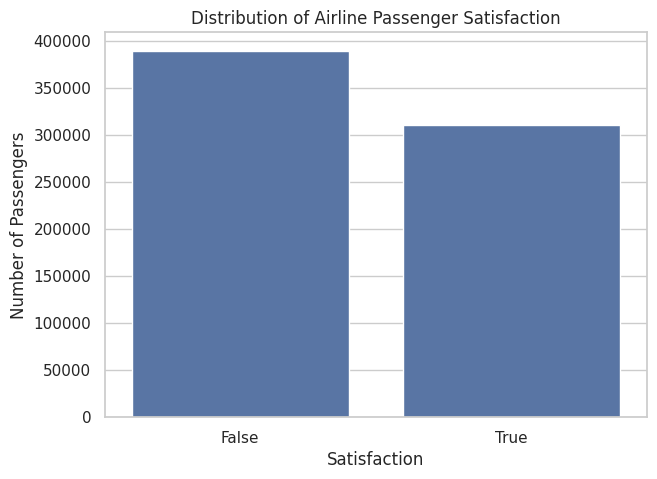

Target proportions:
satisfaction
False    0.5564
True     0.4436
Name: proportion, dtype: float64


In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=train, x='satisfaction', ax=ax)
ax.set_title('Distribution of Airline Passenger Satisfaction')
ax.set_xlabel('Satisfaction')
ax.set_ylabel('Number of Passengers')
plt.show()

print("Target proportions:")
print(train['satisfaction'].value_counts(normalize=True).round(4))

## 5. Numerical Feature Distributions

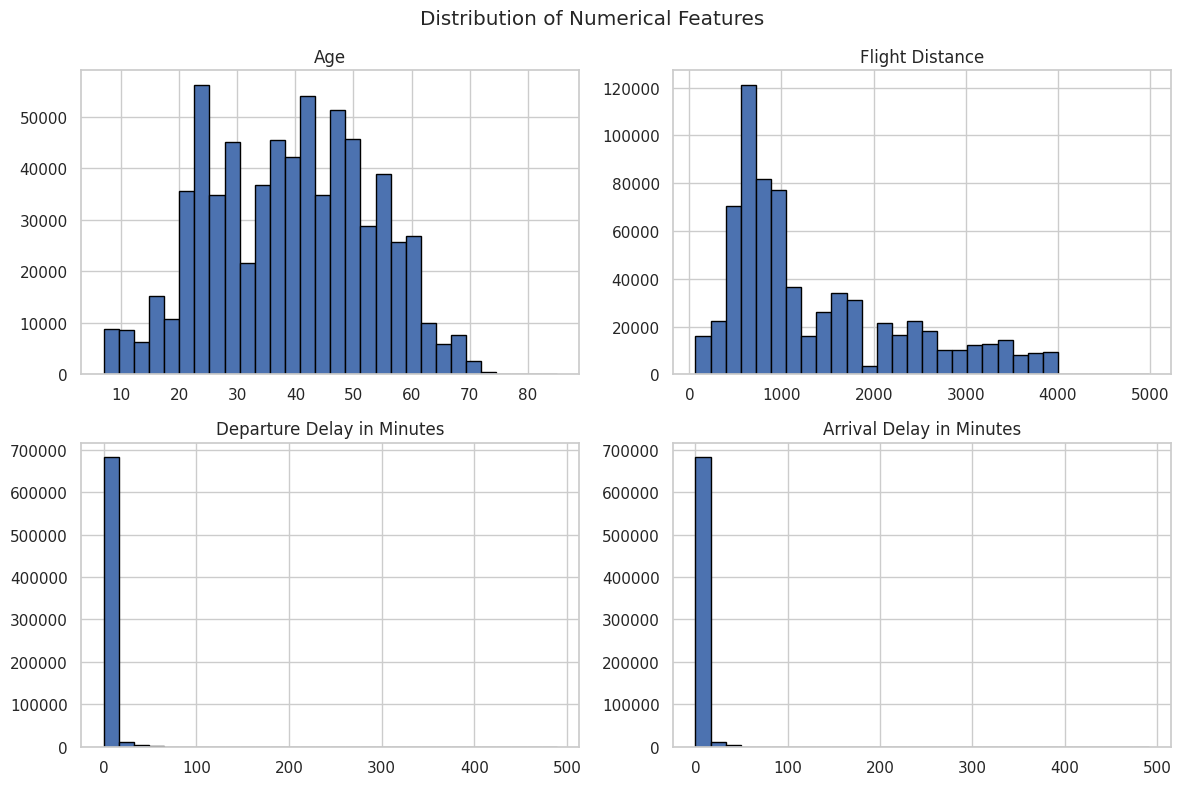

In [5]:
numeric_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']
axes = train[numeric_cols].hist(figsize=(12, 8), bins=30, edgecolor='black')
fig = axes.ravel()[0].get_figure()
fig.suptitle('Distribution of Numerical Features')
fig.tight_layout()
plt.show()

## 6. Categorical Feature Distributions

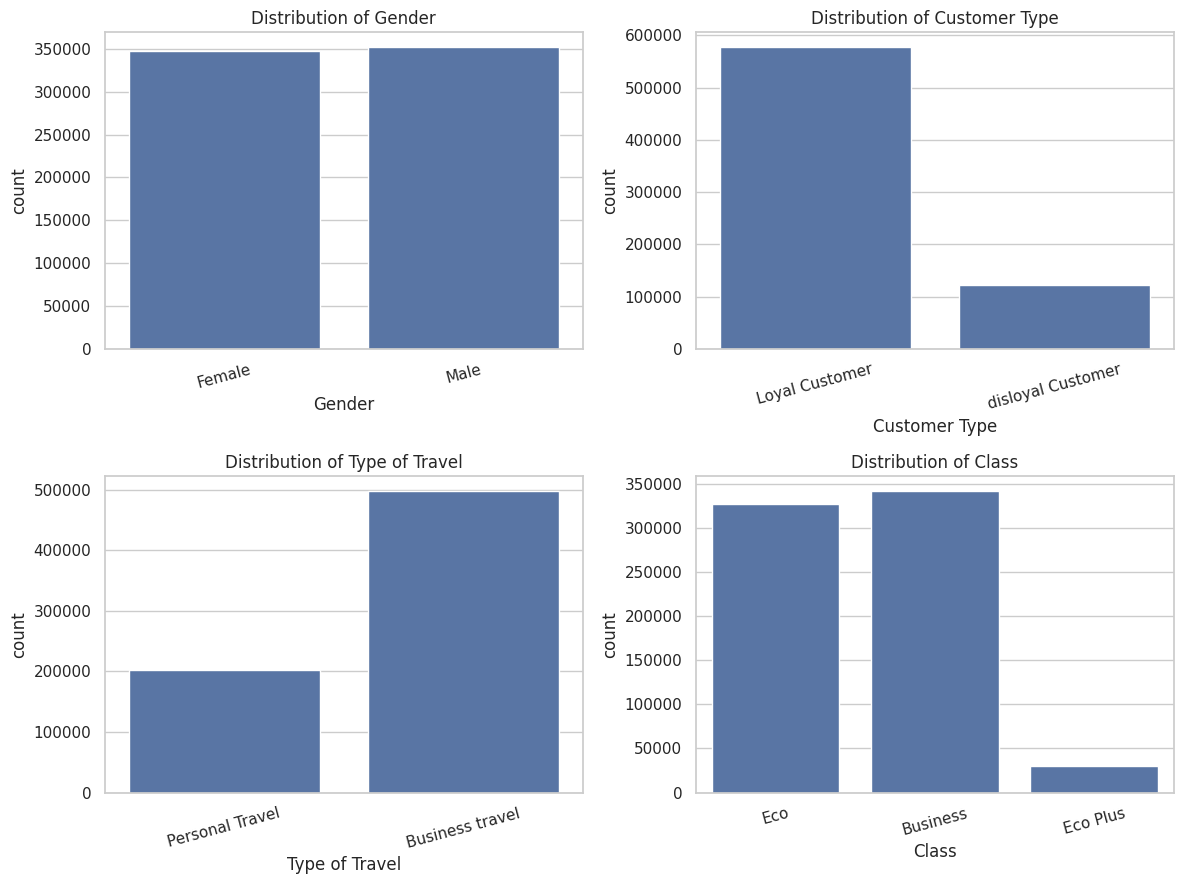

In [6]:
categorical_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for col, ax in zip(categorical_cols, axes.flatten()):
    sns.countplot(data=train, x=col, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.tick_params(axis='x', rotation=15)
fig.tight_layout()
plt.show()

## 7. Service Ratings vs. Target

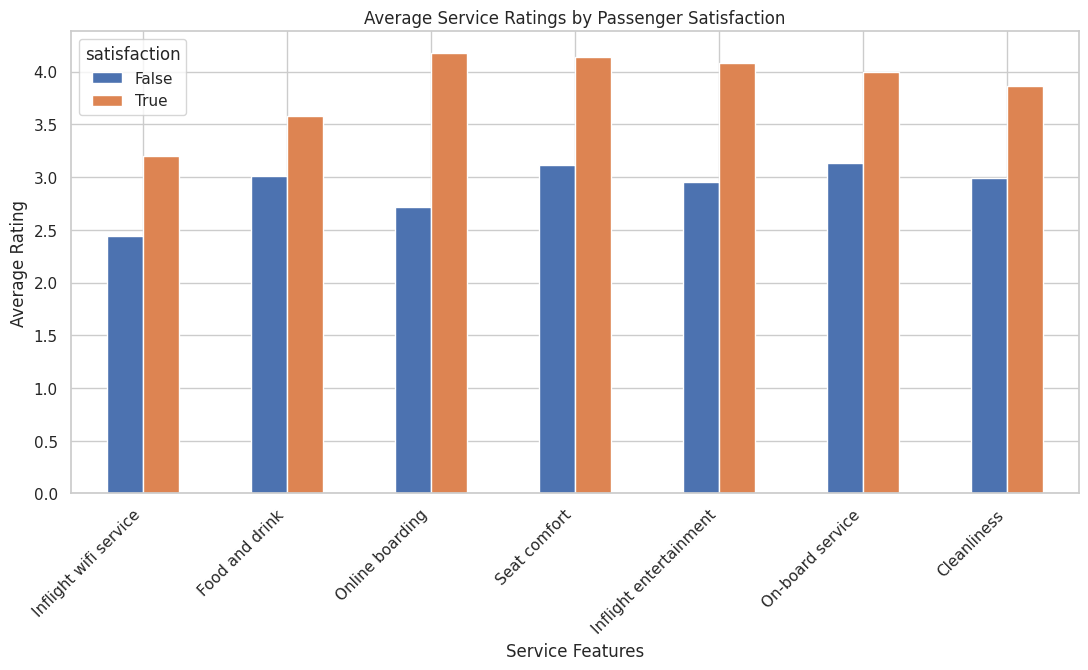

In [7]:
rating_cols = [
    'Inflight wifi service', 'Food and drink', 'Online boarding',
    'Seat comfort', 'Inflight entertainment', 'On-board service', 'Cleanliness'
]
fig, ax = plt.subplots(figsize=(13, 6))
train.groupby('satisfaction')[rating_cols].mean().T.plot(kind='bar', ax=ax)
ax.set_title('Average Service Ratings by Passenger Satisfaction')
ax.set_xlabel('Service Features')
ax.set_ylabel('Average Rating')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.show()

## 8. Satisfaction by Categorical Segments

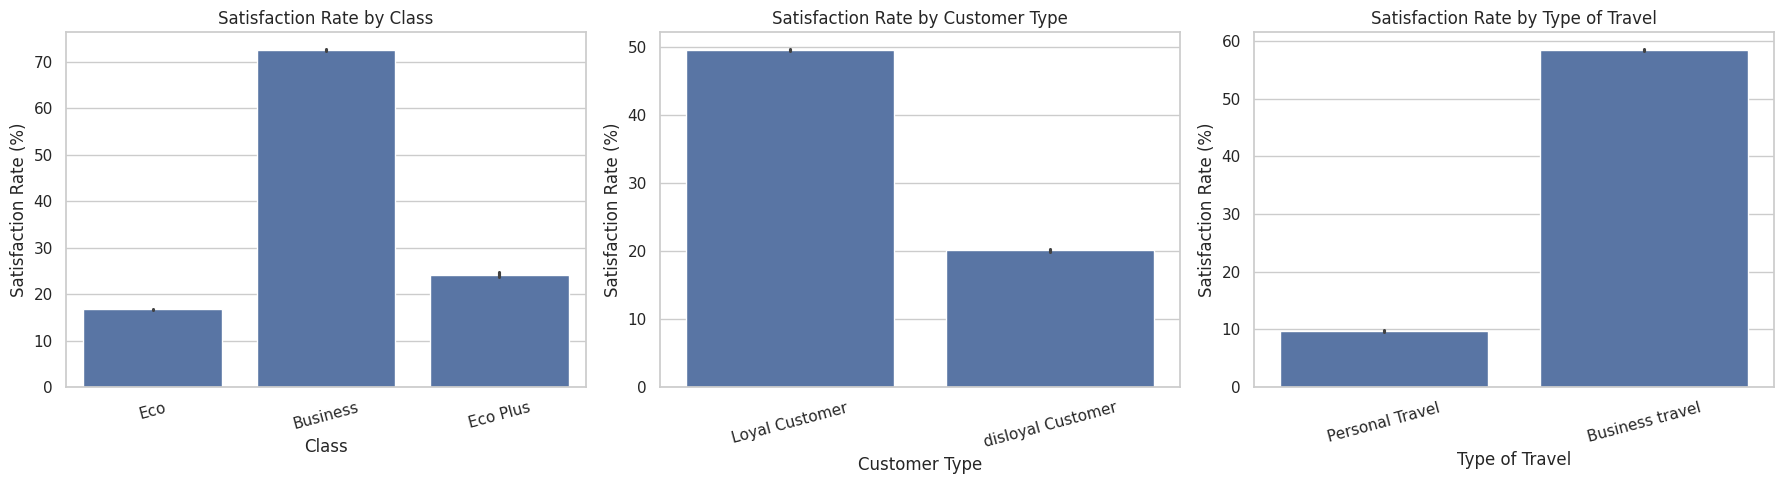

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['Class', 'Customer Type', 'Type of Travel']):
    sns.barplot(data=train, x=col, y='satisfaction', estimator=lambda x: x.mean() * 100, ax=ax)
    ax.set_title(f'Satisfaction Rate by {col}')
    ax.set_ylabel('Satisfaction Rate (%)')
    ax.tick_params(axis='x', rotation=15)
fig.tight_layout()
plt.show()

## 9. Correlation Matrix

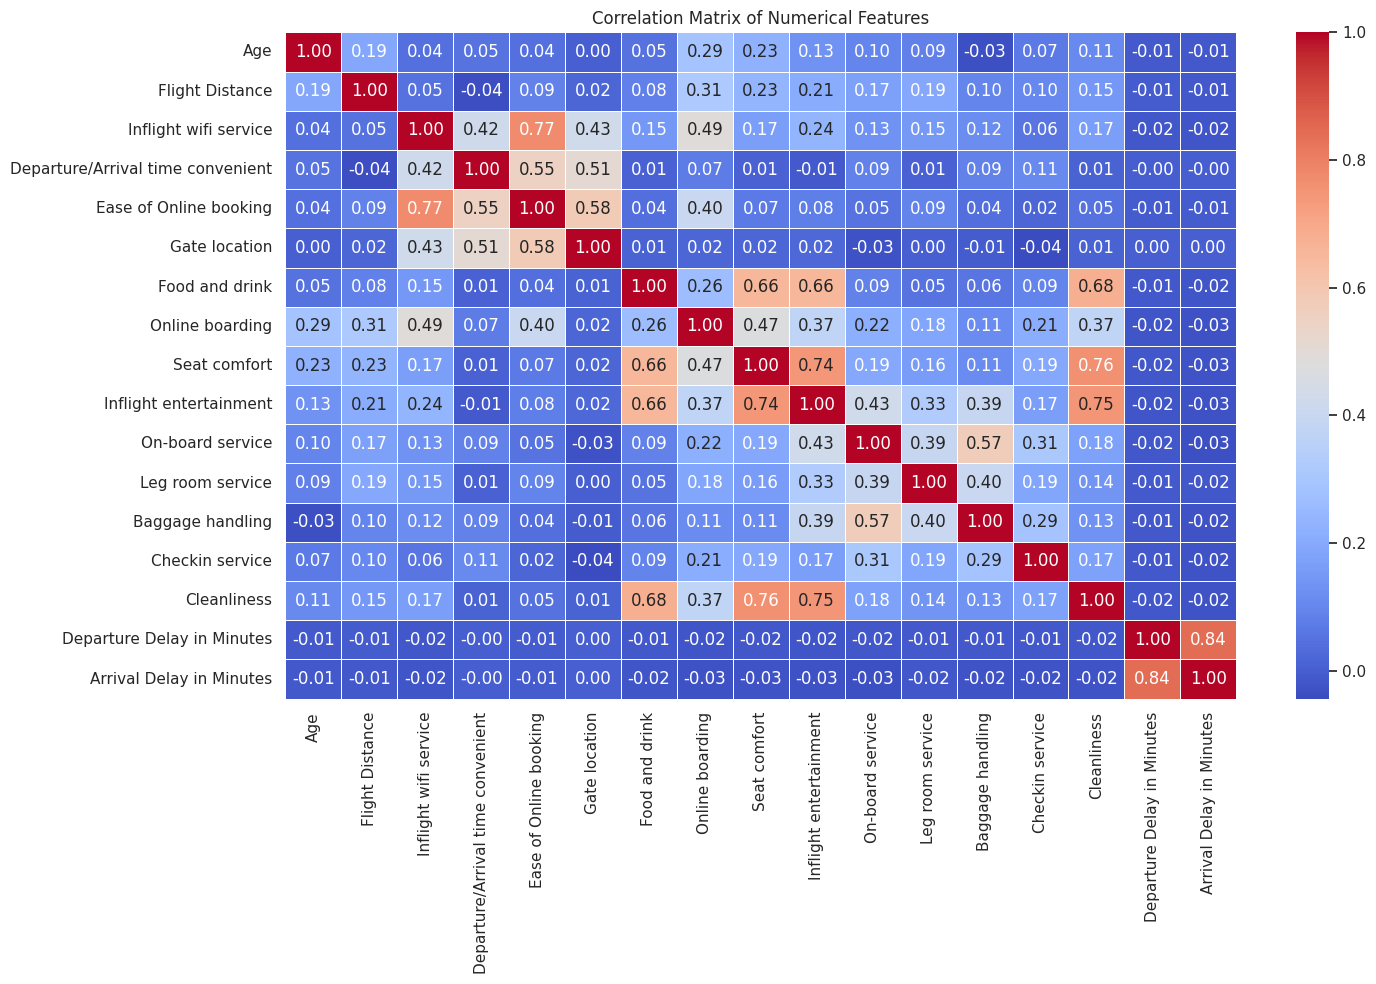

In [9]:
numeric_data = train.select_dtypes(include=np.number).drop(columns=['id'], errors='ignore')
fig, ax = plt.subplots(figsize=(15, 10))
sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix of Numerical Features')
fig.tight_layout()
plt.show()

## 10. Delay Outliers & 11. Missing Values Summary

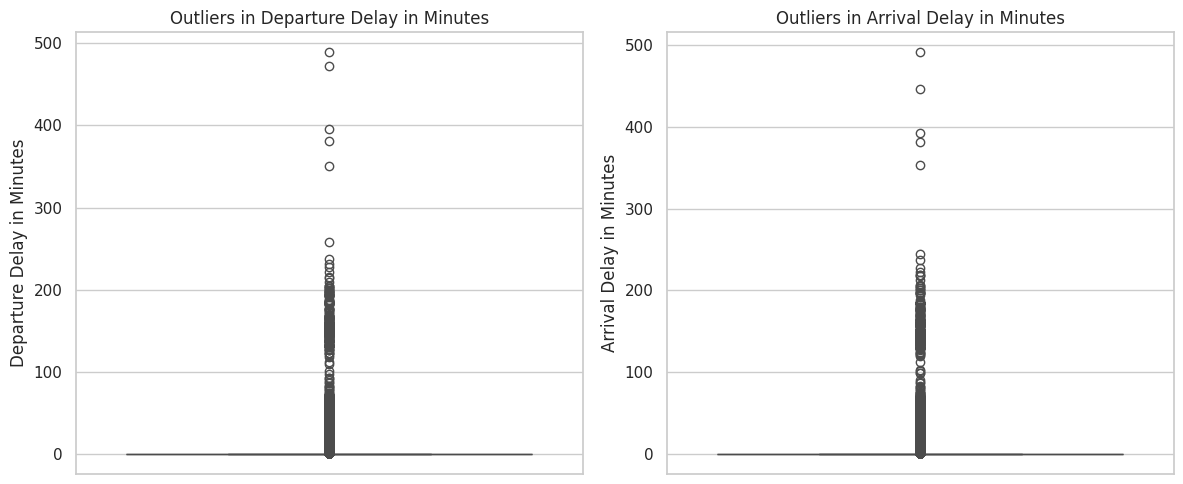

,Missing Values,Percentage (%)
Arrival Delay in Minutes,292,0.041736


In [10]:
delay_cols = ['Departure Delay in Minutes', 'Arrival Delay in Minutes']
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, delay_cols):
    sns.boxplot(y=train[col], ax=ax)
    ax.set_title(f'Outliers in {col}')
fig.tight_layout()
plt.show()

missing_values = train.isnull().sum()
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': (missing_values / len(train)) * 100
})
display(missing_summary[missing_summary['Missing Values'] > 0])

## 12. Features, Target, Train/Validation Split & 13. Preprocessing Pipeline

In [11]:
X = train.drop(columns=['satisfaction', 'id'])
y = train['satisfaction']

numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTraining: {X_train.shape} | Validation: {X_val.shape}")

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])
print("Preprocessing pipeline built successfully.")

Numerical features: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']
Categorical features: ['Gender', 'Customer Type', 'Type of Travel', 'Class']

Training: (559708, 21) | Validation: (139927, 21)
Preprocessing pipeline built successfully.


## 14. Baseline + Logistic Regression Validation

In [12]:
results = {}

baseline_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])
baseline_model.fit(X_train, y_train)
base_pred  = baseline_model.predict(X_val)
base_proba = baseline_model.predict_proba(X_val)[:, 1]
results['Baseline (most frequent)'] = {
    'Accuracy': accuracy_score(y_val, base_pred),
    'ROC-AUC':  roc_auc_score(y_val, base_proba),
}

log_reg_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])
log_reg_model.fit(X_train, y_train)
lr_pred  = log_reg_model.predict(X_val)
lr_proba = log_reg_model.predict_proba(X_val)[:, 1]
results['Logistic Regression'] = {
    'Accuracy': accuracy_score(y_val, lr_pred),
    'ROC-AUC':  roc_auc_score(y_val, lr_proba),
}

results_df = pd.DataFrame(results).T.round(4)
results_df.index.name = 'Model'
display(results_df)
print(classification_report(y_val, lr_pred, digits=4))

,Accuracy,ROC-AUC
Model,,
Baseline (most frequent),0.5564,0.5000
Logistic Regression,0.8781,0.9205


              precision    recall  f1-score   support

       False     0.8805    0.9035    0.8919     77859
        True     0.8748    0.8462    0.8603     62068

    accuracy                         0.8781    139927
   macro avg     0.8777    0.8749    0.8761    139927
weighted avg     0.8780    0.8781    0.8779    139927



## 15. Generate Kaggle Submission

In [13]:
test_ids = test['id']
X_test = test.drop(columns=['id'])

test_probabilities = log_reg_model.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({
    'id': test_ids,
    'satisfaction': test_probabilities,
})
submission.to_csv('submission.csv', index=False)
print("submission.csv written. Row count:", len(submission))
display(submission.head())

submission.csv written. Row count: 299844


,id,satisfaction
0,699635,0.088729
1,699636,0.581899
2,699637,0.470901
3,699638,0.136506
4,699639,0.003213


## 16. Summary: Work Done so far

### Work Done (Intermediate Report)
* Loaded `699,635 x 23` train data and matching test set.
* Documented every feature and its meaning.
* Completed EDA with plots: target balance, numeric distributions, categorical distributions, service ratings vs. target, segment satisfaction rates, correlations, and delay outliers.
* Handled missing values (`Arrival Delay in Minutes`, ~0.04%) via median imputation inside a leak-free `ColumnTransformer` pipeline.
* Scored a trivial baseline (`DummyClassifier`) and `LogisticRegression` on a stratified 80/20 hold-out split using **ROC-AUC**.
* Generated `submission.csv` with predicted probabilities for Kaggle.


